# Baseline 2 — MedMamba Chest X-ray Classifier
### Real MedMamba VSSM → 512-D → 14-class multi-label classifier

This notebook mirrors the evaluation/output structure of the supplied reference notebook and adds research-useful plots plus an interactive prediction UI.

## 1. Environment setup & GPU check

In [1]:

import sys, subprocess, platform, os, pathlib, glob, time, warnings, importlib.util
warnings.filterwarnings("ignore")

import torch

print("=" * 70)
print("MedMamba Baseline 2 — Environment")
print("=" * 70)
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("CUDA avail. :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not available. Start this notebook in the GPU/HPC session."
    )

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9

print("GPU         :", GPU_NAME)
print(f"GPU memory  : {GPU_MEM_GB:.1f} GB")
print("CUDA        :", torch.version.cuda)
print("Device      :", DEVICE)

REQUIRED = {
    "cv2": "opencv-python-headless",
    "sklearn": "scikit-learn",
    "tqdm": "tqdm",
    "einops": "einops",
    "timm": "timm",
    "kagglehub": "kagglehub",
}

missing = [
    pip_name for module_name, pip_name in REQUIRED.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--user", *missing]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sklearn
import torchvision
import torch.nn as nn

torch.backends.cudnn.benchmark = True
if hasattr(torch, "set_float32_matmul_precision"):
    torch.set_float32_matmul_precision("high")

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = min(8, os.cpu_count() or 2)
AMP_ENABLED = True

# Safety switch: leave False for final evaluation using the saved checkpoint.
RUN_TRAINING = False

print("\nConfiguration:")
print("Batch size  :", BATCH_SIZE)
print("Num workers :", NUM_WORKERS)
print("AMP         :", AMP_ENABLED)
print("RUN_TRAINING:", RUN_TRAINING)


MedMamba Baseline 2 — Environment
Python      : 3.12.6
PyTorch     : 2.13.0+cu130
CUDA avail. : True
GPU         : NVIDIA H200 NVL
GPU memory  : 150.1 GB
CUDA        : 13.0
Device      : cuda

Configuration:
Batch size  : 32
Num workers : 8
AMP         : True
RUN_TRAINING: False


## 2. Dataset

In [2]:

import kagglehub

downloaded_path = kagglehub.dataset_download(
    "khanfashee/nih-chest-x-ray-14-224x224-resized"
)
DATA_ROOT = pathlib.Path(downloaded_path)

print("Dataset root:", DATA_ROOT)


Dataset root: /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3


## 3. Locate metadata and images

In [3]:

expected_csv = DATA_ROOT / "Data_Entry_2017.csv"
expected_img_dir = DATA_ROOT / "images-224" / "images-224"

if expected_csv.exists() and expected_img_dir.is_dir():
    LABELS_CSV = str(expected_csv)
    image_files = glob.glob(str(expected_img_dir / "*.png"))
else:
    csv_candidates = sorted(set(
        glob.glob(str(DATA_ROOT / "**" / "*Data_Entry*.csv"), recursive=True)
        + glob.glob(str(DATA_ROOT / "**" / "*.csv"), recursive=True)
    ))
    if not csv_candidates:
        raise FileNotFoundError("No NIH ChestX-ray14 metadata CSV was found.")
    LABELS_CSV = csv_candidates[0]

    image_files = glob.glob(str(DATA_ROOT / "**" / "*.png"), recursive=True)
    if not image_files:
        raise FileNotFoundError("No PNG images were found in the dataset.")

IMAGE_INDEX = {os.path.basename(p): p for p in image_files}

print("Metadata CSV:", LABELS_CSV)
print("Image files :", len(image_files))


Metadata CSV: /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
Image files : 112120


## 4. Labels and 14-class multi-hot targets

In [4]:

DISEASES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia",
]

df = pd.read_csv(LABELS_CSV)
df.columns = [c.strip() for c in df.columns]

image_col = "Image Index" if "Image Index" in df.columns else df.columns[0]
label_col = "Finding Labels" if "Finding Labels" in df.columns else df.columns[1]

df["filepath"] = df[image_col].map(IMAGE_INDEX)
before = len(df)
df = df[df["filepath"].notna()].reset_index(drop=True)

def to_multihot(label_str):
    labels = str(label_str).split("|")
    vec = np.zeros(len(DISEASES), dtype=np.float32)
    for label in labels:
        if label.strip() in DISEASES:
            vec[DISEASES.index(label.strip())] = 1.0
    return vec

label_matrix = np.stack(df[label_col].map(to_multihot).values)

for i, disease in enumerate(DISEASES):
    df[disease] = label_matrix[:, i]

print(f"Matched images: {len(df):,}/{before:,}")
print(f"Dataframe shape: {df.shape}")
print(f"No Finding rows : {(label_matrix.sum(axis=1) == 0).sum():,}")


Matched images: 112,120/112,120
Dataframe shape: (112120, 27)
No Finding rows : 60,412


## 5. Patient-wise 70/15/15 split

In [5]:

from sklearn.model_selection import GroupShuffleSplit

patient_col = "Patient ID" if "Patient ID" in df.columns else None
groups = df[patient_col] if patient_col else df[image_col]

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(df, groups=groups))

temp_df = df.iloc[temp_idx].reset_index(drop=True)
temp_groups = temp_df[patient_col] if patient_col else temp_df[image_col]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_groups))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(train_df):,}")
print(f"Val  : {len(val_df):,}")
print(f"Test : {len(test_df):,}")

if patient_col:
    train_patients = set(train_df[patient_col])
    val_patients = set(val_df[patient_col])
    test_patients = set(test_df[patient_col])

    assert not (train_patients & val_patients)
    assert not (train_patients & test_patients)
    assert not (val_patients & test_patients)

    print("Patient-wise split verified: no overlap.")
else:
    print("WARNING: Patient ID unavailable; image-level grouping used.")


Train: 78,566
Val  : 16,106
Test : 17,448
Patient-wise split verified: no overlap.


## 6. Preprocessing — CLAHE + Unsharp Masking

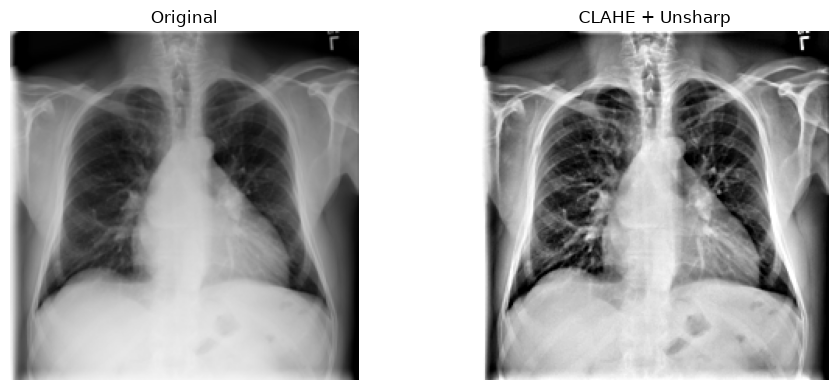

In [6]:

def clahe_unsharp(img):
    if img is None:
        raise ValueError("OpenCV could not read the image.")

    if img.ndim == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    blurred = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=3)
    sharpened = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)

    return cv2.cvtColor(sharpened, cv2.COLOR_GRAY2BGR)

sample_path = train_df.iloc[0]["filepath"]
raw = cv2.imread(sample_path)
processed = clahe_unsharp(raw)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
axes[1].set_title("CLAHE + Unsharp")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 7. PyTorch Dataset / DataLoaders

In [7]:

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, train=False):
        self.df = dataframe.reset_index(drop=True)
        augmentation = [transforms.RandomHorizontalFlip()] if train else []

        self.transform = transforms.Compose(
            augmentation + [
                transforms.Resize((IMG_SIZE, IMG_SIZE)),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225],
                ),
            ]
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["filepath"])
        img = clahe_unsharp(img)
        img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        img = self.transform(img)

        label = torch.tensor(
            row[DISEASES].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )
        return img, label

train_ds = ChestXrayDataset(train_df, train=True)
val_ds = ChestXrayDataset(val_df, train=False)
test_ds = ChestXrayDataset(test_df, train=False)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

print(f"Train loader: {len(train_ds):,} images / {len(train_loader):,} batches")
print(f"Val loader  : {len(val_ds):,} images / {len(val_loader):,} batches")
print(f"Test loader : {len(test_ds):,} images / {len(test_loader):,} batches")


Train loader: 78,566 images / 2,456 batches
Val loader  : 16,106 images / 504 batches
Test loader : 17,448 images / 546 batches


## 8. Load the real official MedMamba VSSM

In [8]:

import importlib.util
import shutil
import subprocess
from pathlib import Path

MEDMAMBA_REPO = "https://github.com/YubiaoYue/MedMamba.git"
BASE_DIR = Path.cwd().resolve()
REPO_DIR = BASE_DIR / "MedMamba"
SRC_PATH = REPO_DIR / "MedMamba.py"

print("Working directory:", BASE_DIR)
print("MedMamba source   :", SRC_PATH)

if not SRC_PATH.is_file():
    if REPO_DIR.exists():
        git_dir = REPO_DIR / ".git"
        if git_dir.is_dir():
            pull = subprocess.run(
                ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
                capture_output=True, text=True
            )
            if pull.returncode == 0 and SRC_PATH.is_file():
                print("Existing repository updated.")
            else:
                shutil.rmtree(REPO_DIR)
        else:
            shutil.rmtree(REPO_DIR)

    if not SRC_PATH.is_file():
        clone = subprocess.run(
            ["git", "clone", MEDMAMBA_REPO, str(REPO_DIR)],
            capture_output=True, text=True
        )
        if clone.returncode != 0:
            raise RuntimeError(
                "Could not clone the official MedMamba repository.\n"
                + clone.stderr
            )

if not SRC_PATH.is_file():
    raise FileNotFoundError(
        f"Official MedMamba.py not found at {SRC_PATH}. "
        "No placeholder model is permitted."
    )

with open(SRC_PATH, "r", encoding="utf-8") as f:
    source_lines = f.readlines()

# Avoid executing the repository's module-level demo model construction.
markers = [i for i, line in enumerate(source_lines)
           if line.startswith("medmamba_t =")]
safe_source = "".join(source_lines[:markers[0]]) if markers else "".join(source_lines)

spec = importlib.util.spec_from_loader("MedMamba_safe", loader=None)
medmamba_module = importlib.util.module_from_spec(spec)
sys.modules["MedMamba_safe"] = medmamba_module

try:
    exec(compile(safe_source, str(SRC_PATH), "exec"), medmamba_module.__dict__)
except Exception as exc:
    raise RuntimeError(
        "The official MedMamba source could not be imported. "
        "Check mamba_ssm / causal-conv1d / CUDA compatibility."
    ) from exc

if not hasattr(medmamba_module, "VSSM"):
    raise RuntimeError("Official MedMamba VSSM class was not found.")

MedMambaBackbone = medmamba_module.VSSM

print("SUCCESS: real MedMamba VSSM loaded.")


Working directory: /home/jupyter-22csr090
MedMamba source   : /home/jupyter-22csr090/MedMamba/MedMamba.py
SUCCESS: real MedMamba VSSM loaded.


## 9. Real MedMamba forward-pass verification

In [9]:

MEDMAMBA_DEPTHS = [2, 2, 4, 2]
MEDMAMBA_DIMS = [64, 128, 256, 512]
MEDMAMBA_OUT_DIM = 512

verification_model = MedMambaBackbone(
    depths=MEDMAMBA_DEPTHS,
    dims=MEDMAMBA_DIMS,
    num_classes=0
).to(DEVICE)

dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)

verification_model.eval()
try:
    with torch.no_grad():
        verification_output = verification_model(dummy)
except Exception as exc:
    del verification_model, dummy
    torch.cuda.empty_cache()
    raise RuntimeError(
        "REAL MEDMAMBA FORWARD PASS FAILED. "
        "Do not replace it with a placeholder model."
    ) from exc

print("Verification output shape:", tuple(verification_output.shape))
assert tuple(verification_output.shape) == (2, MEDMAMBA_OUT_DIM)

del verification_model, dummy, verification_output
torch.cuda.empty_cache()

print("SUCCESS: real MedMamba forward pass verified.")


Verification output shape: (2, 512)
SUCCESS: real MedMamba forward pass verified.


## 10. MedMamba baseline model

In [10]:

class MedMambaClassifier(nn.Module):
    def __init__(self, num_classes=14):
        super().__init__()
        self.backbone = MedMambaBackbone(
            depths=MEDMAMBA_DEPTHS,
            dims=MEDMAMBA_DIMS,
            num_classes=0
        )
        self.feature_dim = MEDMAMBA_OUT_DIM
        self.classifier = nn.Linear(self.feature_dim, num_classes)

    def forward(self, x, return_features=False):
        features = self.backbone(x)
        logits = self.classifier(features)
        return (logits, features) if return_features else logits

model = MedMambaClassifier(num_classes=len(DISEASES)).to(DEVICE)

TOTAL_PARAMS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model              : MedMambaClassifier")
print("Feature dimension   :", model.feature_dim)
print("Classifier outputs  :", len(DISEASES))
print(f"Total parameters    : {TOTAL_PARAMS:,}")
print(f"Trainable parameters: {TRAINABLE_PARAMS:,}")

model.eval()
with torch.no_grad():
    sample_imgs, _ = next(iter(val_loader))
    sample_logits, sample_features = model(
        sample_imgs[:2].to(DEVICE), return_features=True
    )

assert tuple(sample_features.shape) == (2, 512)
assert tuple(sample_logits.shape) == (2, 14)

print("Smoke test PASSED.")


Model              : MedMambaClassifier
Feature dimension   : 512
Classifier outputs  : 14
Total parameters    : 6,609,166
Trainable parameters: 6,609,166
Smoke test PASSED.


## 11. Loss, optimizer and optional training

In [11]:
pos_counts = train_df[DISEASES].sum().to_numpy(dtype=np.float64)
neg_counts = len(train_df) - pos_counts

pos_weight = torch.tensor(
    neg_counts / np.clip(pos_counts, 1, None),
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

EPOCHS = 50

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# IMPORTANT: enable actual training
RUN_TRAINING = True

print("Loss      : BCEWithLogitsLoss + training-set pos_weight")
print("Optimizer : AdamW")
print("LR        : 2e-4")
print("Epochs    :", EPOCHS)
print("Training  :", "ENABLED" if RUN_TRAINING else "DISABLED (test-only mode)")

Loss      : BCEWithLogitsLoss + training-set pos_weight
Optimizer : AdamW
LR        : 2e-4
Epochs    : 50
Training  : ENABLED


In [12]:

from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

def mean_auroc(y_true, y_prob):
    aucs = []
    for i in range(y_true.shape[1]):
        if len(np.unique(y_true[:, i])) >= 2:
            aucs.append(roc_auc_score(y_true[:, i], y_prob[:, i]))
    return (float(np.mean(aucs)) if aucs else float("nan")), aucs

CHECKPOINT_PATH = "/home/jupyter-22csr090/best_medmamba_checkpoint.pth"

history = {"train_loss": [], "val_loss": [], "val_auroc": []}
best_val_auroc = -np.inf
best_epoch = 0

if RUN_TRAINING:
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

    print(f"Starting MedMamba training for {EPOCHS} epochs...")

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()

        model.train()
        running_loss = 0.0

        train_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]",
            unit="batch",
            mininterval=5.0,
            leave=False
        )

        for imgs, labels in train_bar:
            imgs = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=AMP_ENABLED
            ):
                logits = model(imgs)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * imgs.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss_sum = 0.0
        all_probs, all_labels = [], []

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]",
            unit="batch",
            mininterval=5.0,
            leave=False
        )

        with torch.no_grad():
            for imgs, labels in val_bar:
                imgs = imgs.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=AMP_ENABLED
                ):
                    logits = model(imgs)
                    loss = criterion(logits, labels)

                val_loss_sum += loss.item() * imgs.size(0)
                all_probs.append(torch.sigmoid(logits).cpu().numpy())
                all_labels.append(labels.cpu().numpy())

        val_loss = val_loss_sum / len(val_loader.dataset)
        all_probs = np.concatenate(all_probs)
        all_labels = np.concatenate(all_labels)
        val_auroc, _ = mean_auroc(all_labels, all_probs)

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_auroc"].append(val_auroc)

        marker = ""
        if val_auroc > best_val_auroc:
            best_val_auroc = val_auroc
            best_epoch = epoch

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "val_auroc": best_val_auroc,
                    "best_val_auroc": best_val_auroc,
                    "feature_dim": model.feature_dim,
                    "model_name": "MedMambaClassifier",
                    "num_classes": len(DISEASES),
                    "diseases": DISEASES,
                },
                CHECKPOINT_PATH
            )
            marker = " <-- BEST CHECKPOINT"

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_AUROC={val_auroc:.4f} | "
            f"time={(time.time()-t0)/60:.1f} min"
            f"{marker}"
        )

    print("\nTraining complete.")
    print(f"Best validation AUROC: {best_val_auroc:.4f}")
    print(f"Best epoch           : {best_epoch}")


Starting MedMamba training for 50 epochs...


Epoch 01/50 [Train]:   0%|          | 0/2456 [00:00<?, ?batch/s]

Epoch 01/50 [Val]:   0%|          | 0/504 [00:00<?, ?batch/s]

Epoch 01/50 | train_loss=1.2542 | val_loss=1.1958 | val_AUROC=0.6981 | time=6.1 min <-- BEST CHECKPOINT


Epoch 02/50 [Train]:   0%|          | 0/2456 [00:00<?, ?batch/s]

...

Epoch 49/50 [Val]:   0%|          | 0/504 [00:00<?, ?batch/s]

Epoch 49/50 | train_loss=0.2639 | val_loss=5.6843 | val_AUROC=0.7349 | time=7.8 min


Epoch 50/50 [Train]:   0%|          | 0/2456 [00:00<?, ?batch/s]

Epoch 50/50 [Val]:   0%|          | 0/504 [00:00<?, ?batch/s]

Epoch 50/50 | train_loss=0.2614 | val_loss=5.6550 | val_AUROC=0.7333 | time=8.7 min

Training complete.
Best validation AUROC: 0.7718
Best epoch           : 10


## 12. Load the saved best checkpoint

In [13]:

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Saved checkpoint not found: {CHECKPOINT_PATH}\n"
        "If you intend to train from scratch, set RUN_TRAINING=True."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

state_dict = checkpoint.get("model_state_dict")
if state_dict is None:
    raise KeyError("Checkpoint does not contain 'model_state_dict'.")

model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

BEST_EPOCH = int(checkpoint.get("epoch", 0))
BEST_VAL_AUROC = float(
    checkpoint.get(
        "val_auroc",
        checkpoint.get("best_val_auroc", float("nan"))
    )
)

print("=" * 70)
print("BEST MEDMAMBA CHECKPOINT LOADED")
print("=" * 70)
print("Checkpoint:", CHECKPOINT_PATH)
print("Best epoch:", BEST_EPOCH)
print("Best validation Macro AUROC:", BEST_VAL_AUROC)
print("Feature dimension:", model.feature_dim)
print("Model:", checkpoint.get("model_name", "MedMambaClassifier"))
print("Device:", DEVICE)
print("=" * 70)


BEST MEDMAMBA CHECKPOINT LOADED
Checkpoint: /home/jupyter-22csr090/best_medmamba_checkpoint.pth
Best epoch: 10
Best validation Macro AUROC: 0.7717597096649154
Feature dimension: 512
Model: MedMambaClassifier
Device: cuda


## 13. Test-set evaluation

In [14]:

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

THRESHOLD = 0.50

test_probs = []
test_labels = []
test_loss_sum = 0.0

model.eval()

test_bar = tqdm(
    test_loader,
    desc="Evaluating MedMamba on test set",
    unit="batch",
    mininterval=5.0
)

with torch.no_grad():
    for imgs, labels in test_bar:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels_gpu = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            logits = model(imgs)
            loss = criterion(logits, labels_gpu)

        test_loss_sum += loss.item() * imgs.size(0)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())
        test_labels.append(labels.cpu().numpy())

test_loss = test_loss_sum / len(test_loader.dataset)
test_probs = np.concatenate(test_probs, axis=0)
test_labels = np.concatenate(test_labels, axis=0)

rows = []

for i, disease in enumerate(DISEASES):
    y_true = test_labels[:, i].astype(int)
    y_prob = test_probs[:, i]
    y_pred = (y_prob >= THRESHOLD).astype(int)

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    auc = (
        roc_auc_score(y_true, y_prob)
        if len(np.unique(y_true)) >= 2
        else np.nan
    )

    rows.append({
        "Disease": disease,
        "AUROC": auc,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

results_df = pd.DataFrame(rows)

macro_accuracy = results_df["Accuracy"].mean()
macro_precision = results_df["Precision"].mean()
macro_recall = results_df["Recall"].mean()
macro_f1 = results_df["F1"].mean()
macro_auroc = results_df["AUROC"].mean()

summary_df = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy (macro)",
        "Precision (macro)",
        "Recall (macro)",
        "F1 (macro)",
        "Macro AUROC",
        "Best validation AUROC",
        "Best epoch",
        "Total parameters",
        "Trainable parameters",
        "Feature dimension",
        "Decision threshold",
    ],
    "Value": [
        test_loss,
        macro_accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        macro_auroc,
        BEST_VAL_AUROC,
        BEST_EPOCH,
        TOTAL_PARAMS,
        TRAINABLE_PARAMS,
        model.feature_dim,
        THRESHOLD,
    ],
})

print("\n===== MEDMAMBA BASELINE — TEST SUMMARY =====")
for _, row in summary_df.iterrows():
    print(f"{row['Metric']:<28}: {row['Value']}")

print("\nPer-class results:")
display(results_df.sort_values("AUROC", ascending=False).reset_index(drop=True))


Evaluating MedMamba on test set:   0%|          | 0/546 [00:00<?, ?batch/s]


===== MEDMAMBA BASELINE — TEST SUMMARY =====
Test Loss                   : 1.098393356182443
Accuracy (macro)            : 0.7127873845549223
Precision (macro)           : 0.1095486621934632
Recall (macro)              : 0.68938707520155
F1 (macro)                  : 0.17505361632706049
Macro AUROC                 : 0.7768700979681242
Best validation AUROC       : 0.7717597096649154
Best epoch                  : 10.0
Total parameters            : 6609166.0
Trainable parameters        : 6609166.0
Feature dimension           : 512.0
Decision threshold          : 0.5

Per-class results:


,Disease,AUROC,Accuracy,Precision,Recall,F1
0,Hernia,0.874479,0.939305,0.014218,0.441176,0.027548
1,Cardiomegaly,0.873167,0.792526,0.099462,0.783838,0.176524
2,Edema,0.865977,0.831499,0.077223,0.712575,0.139344
3,Pneumothorax,0.842801,0.668443,0.113643,0.871856,0.201077
4,Effusion,0.832863,0.758884,0.293018,0.754050,0.422036
5,Emphysema,0.815089,0.645060,0.060396,0.832627,0.112624
6,Consolidation,0.771788,0.696470,0.099203,0.726329,0.174564
7,Fibrosis,0.748717,0.599782,0.029865,0.768953,0.057498
8,Atelectasis,0.741360,0.677785,0.190224,0.675968,0.296898
9,Pleural_Thickening,0.739911,0.659904,0.060280,0.690299,0.110878


## 14. Additional research plots — class distribution, heatmap and violin chart


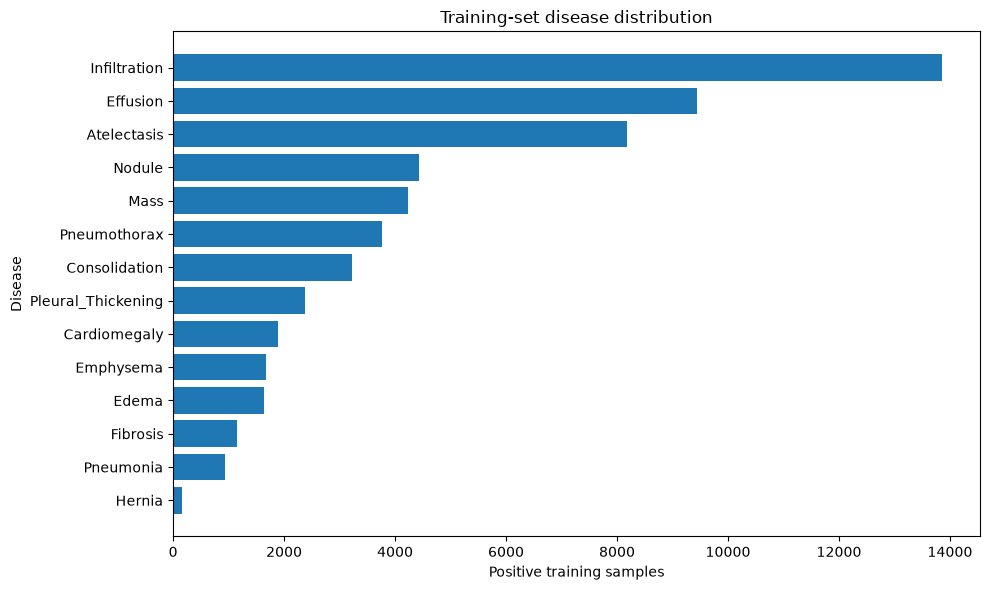

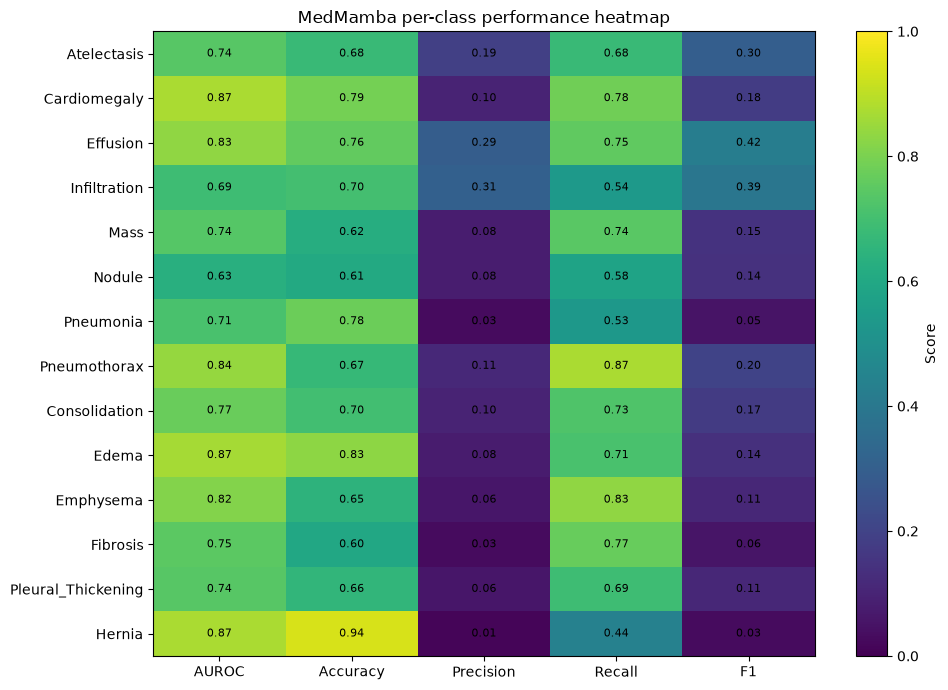

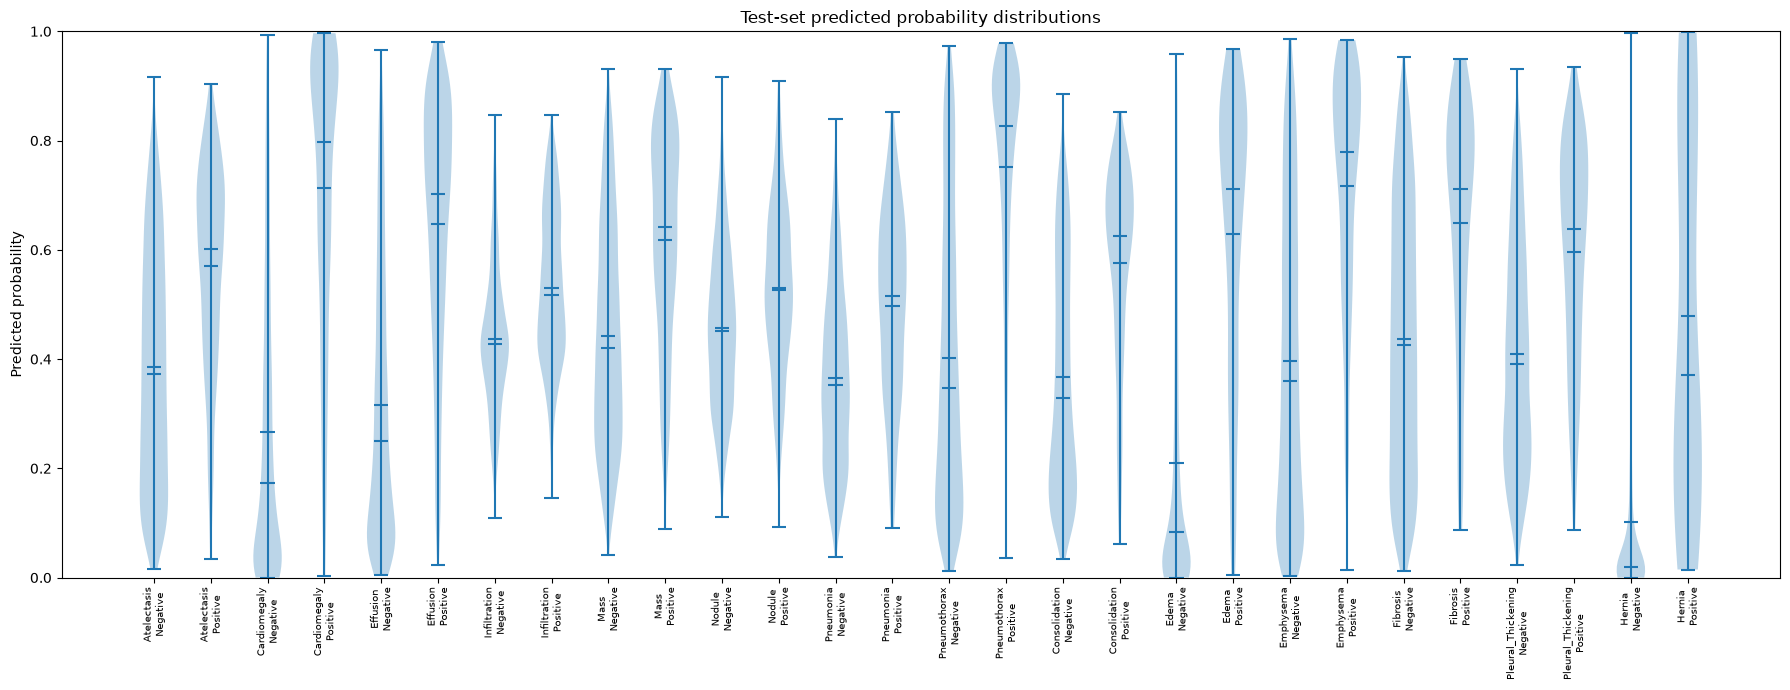

In [15]:
# Class distribution on the training split
class_counts = train_df[DISEASES].sum().sort_values(ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(class_counts.index, class_counts.values)
plt.xlabel('Positive training samples')
plt.ylabel('Disease')
plt.title('Training-set disease distribution')
plt.tight_layout()
plt.show()

# Per-class metric heatmap (matplotlib only; no extra seaborn dependency)
heat_cols = ['AUROC', 'Accuracy', 'Precision', 'Recall', 'F1']
heat = results_df.set_index('Disease')[heat_cols].copy()
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(heat.to_numpy(dtype=float), aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(heat_cols)))
ax.set_xticklabels(heat_cols)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        value = heat.iloc[r, c]
        if pd.notna(value):
            ax.text(c, r, f'{value:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Score')
ax.set_title('MedMamba per-class performance heatmap')
plt.tight_layout()
plt.show()

# Violin plot of predicted probabilities for positive/negative examples.
# Sample at most 5000 examples per class to keep the plot lightweight.
rng = np.random.default_rng(42)
violin_data = []
violin_labels = []
for i, disease in enumerate(DISEASES):
    y = test_labels[:, i].astype(int)
    p = test_probs[:, i]
    for cls, name in [(0, 'Negative'), (1, 'Positive')]:
        vals = p[y == cls]
        if len(vals) > 5000:
            vals = rng.choice(vals, 5000, replace=False)
        if len(vals):
            violin_data.append(vals)
            violin_labels.append(f'{disease}\n{name}')

plt.figure(figsize=(18, 7))
positions = np.arange(1, len(violin_data) + 1)
plt.violinplot(violin_data, positions=positions, showmeans=True, showmedians=True)
plt.xticks(positions, violin_labels, rotation=90, fontsize=7)
plt.ylabel('Predicted probability')
plt.ylim(0, 1)
plt.title('Test-set predicted probability distributions')
plt.tight_layout()
plt.show()


## 15. Prediction-score correlation heatmap


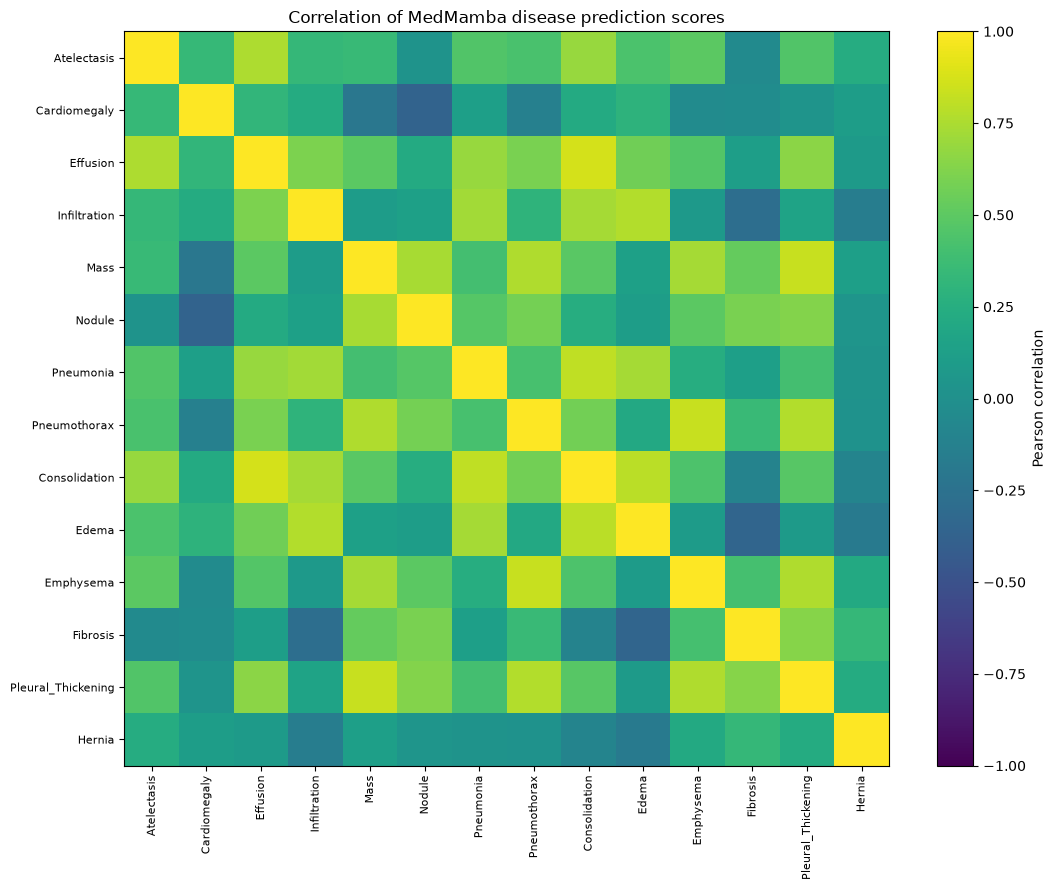

In [16]:
corr = np.corrcoef(test_probs.T)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(DISEASES)))
ax.set_xticklabels(DISEASES, rotation=90, fontsize=8)
ax.set_yticks(range(len(DISEASES)))
ax.set_yticklabels(DISEASES, fontsize=8)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Correlation of MedMamba disease prediction scores')
plt.tight_layout()
plt.show()


## 16. Per-class AUROC

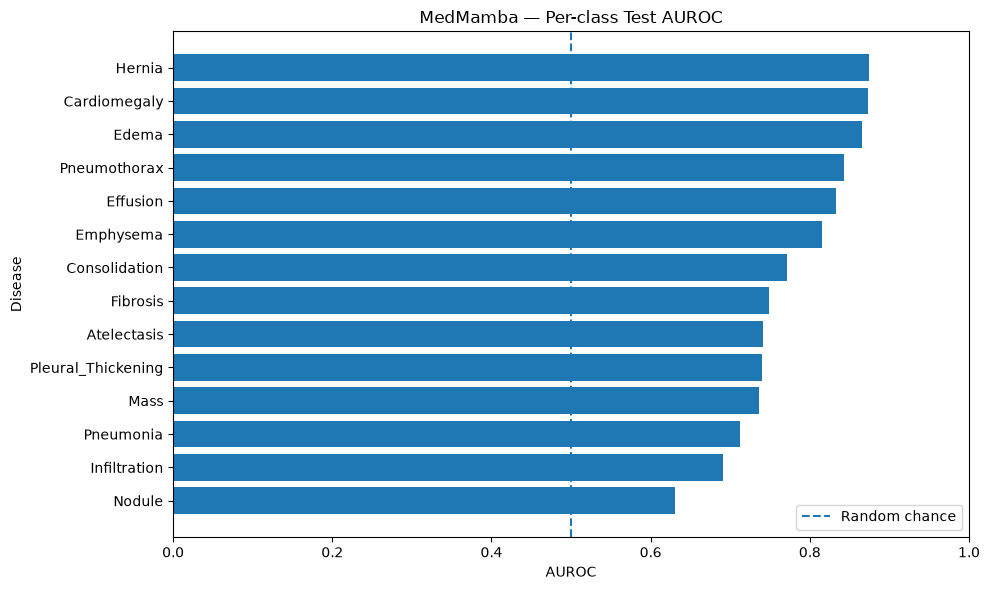

In [17]:

plot_df = results_df.dropna(subset=["AUROC"]).sort_values("AUROC")

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Disease"], plot_df["AUROC"])
plt.axvline(0.5, linestyle="--", label="Random chance")
plt.xlim(0.0, 1.0)
plt.xlabel("AUROC")
plt.ylabel("Disease")
plt.title("MedMamba — Per-class Test AUROC")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Per-class ROC curves

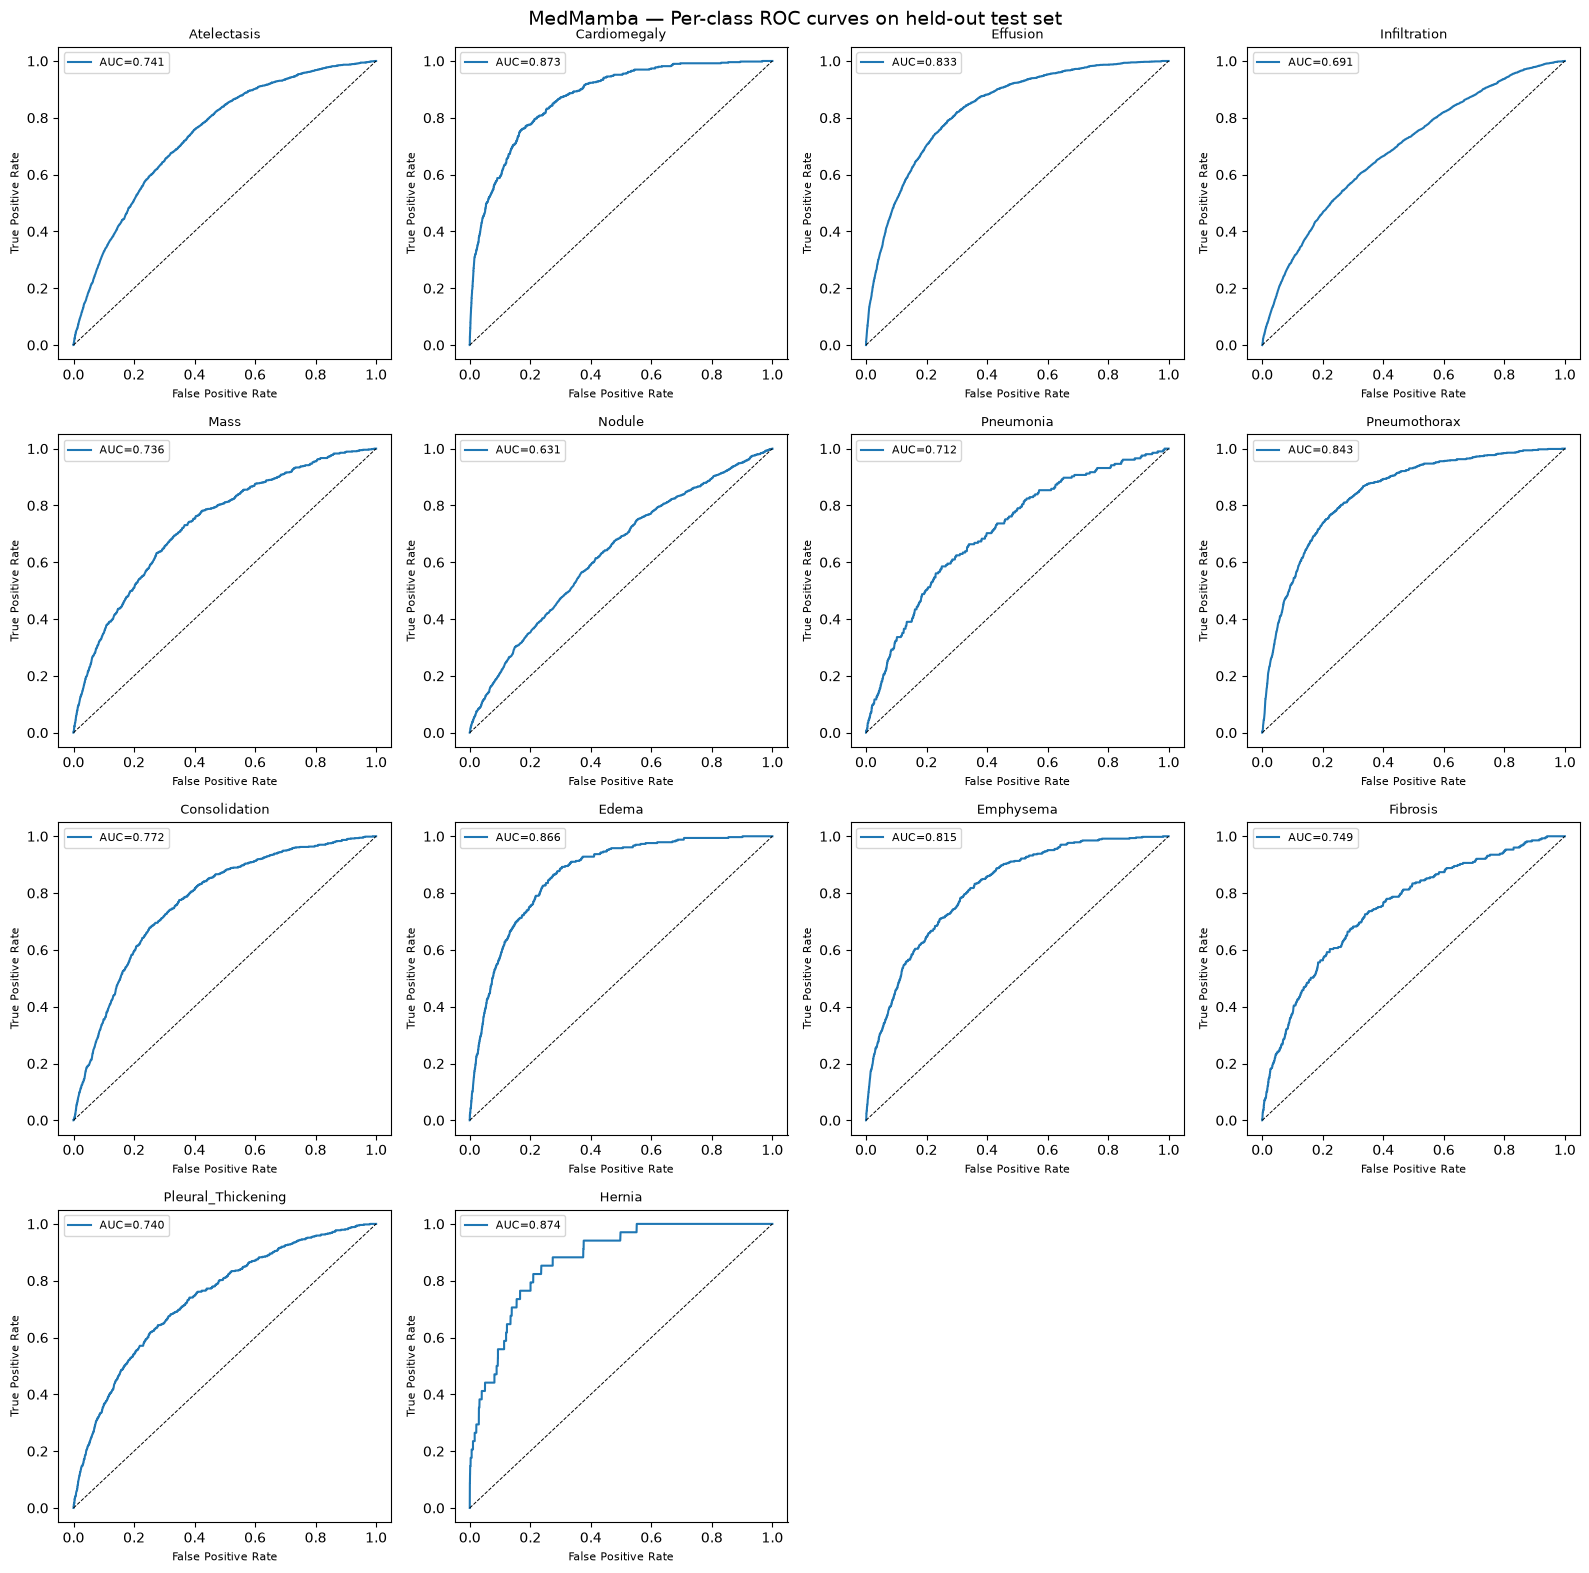

In [18]:

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.ravel()

for i, disease in enumerate(DISEASES):
    ax = axes[i]
    y_true = test_labels[:, i].astype(int)
    y_prob = test_probs[:, i]

    if len(np.unique(y_true)) < 2:
        ax.text(0.5, 0.5, "AUROC undefined", ha="center", va="center")
        ax.set_title(disease, fontsize=9)
        ax.axis("off")
        continue

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    ax.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.7)
    ax.set_title(disease, fontsize=9)
    ax.set_xlabel("False Positive Rate", fontsize=8)
    ax.set_ylabel("True Positive Rate", fontsize=8)
    ax.legend(fontsize=8)

for j in range(len(DISEASES), len(axes)):
    axes[j].axis("off")

plt.suptitle("MedMamba — Per-class ROC curves on held-out test set", fontsize=14)
plt.tight_layout()
plt.show()


## 18. Save results

In [19]:

OUTPUT_DIR = Path.cwd() / "medmamba_baseline_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

RESULTS_CSV = OUTPUT_DIR / "medmamba_baseline_per_class_results.csv"
SUMMARY_CSV = OUTPUT_DIR / "medmamba_baseline_summary.csv"

results_df.to_csv(RESULTS_CSV, index=False)
summary_df.to_csv(SUMMARY_CSV, index=False)

print("Saved:")
print(" -", RESULTS_CSV)
print(" -", SUMMARY_CSV)


Saved:
 - /home/jupyter-22csr090/medmamba_baseline_outputs/medmamba_baseline_per_class_results.csv
 - /home/jupyter-22csr090/medmamba_baseline_outputs/medmamba_baseline_summary.csv


## 20. Final Test Results Dashboard

In [20]:

from IPython.display import display, HTML

def pct(x):
    return f"{100*x:.2f}%" if pd.notna(x) else "N/A"

cards = [
    ("Test Loss", f"{test_loss:.4f}"),
    ("Macro AUROC", pct(macro_auroc)),
    ("Macro F1", pct(macro_f1)),
    ("Macro Precision", pct(macro_precision)),
    ("Macro Recall", pct(macro_recall)),
    ("Macro Accuracy", pct(macro_accuracy)),
    ("Best Val AUROC", pct(BEST_VAL_AUROC)),
    ("Best Epoch", str(BEST_EPOCH)),
]

card_html = "".join(
    f"""
    <div style="
        flex:1 1 180px;
        border:1px solid #d9d9d9;
        border-radius:12px;
        padding:18px;
        margin:6px;
        background:#fafafa;
        box-shadow:0 1px 4px rgba(0,0,0,0.08);
    ">
        <div style="font-size:13px;color:#666;">{label}</div>
        <div style="font-size:27px;font-weight:700;margin-top:6px;">{value}</div>
    </div>
    """
    for label, value in cards
)

dashboard = f"""
<div style="font-family:Arial,sans-serif;max-width:1100px;">
    <h2 style="margin-bottom:4px;">MedMamba Baseline 2 — Test Results</h2>
    <p style="color:#666;margin-top:0;">
        NIH ChestX-ray14 · Patient-wise 70/15/15 · Real MedMamba VSSM · 512-D · Threshold={THRESHOLD:.2f}
    </p>

    <div style="display:flex;flex-wrap:wrap;margin:-6px;">
        {card_html}
    </div>

    <div style="
        margin-top:18px;
        padding:15px;
        border-radius:10px;
        background:#f3f3f3;
    ">
        <b>Model:</b> MedMambaClassifier &nbsp; | &nbsp;
        <b>Parameters:</b> {TOTAL_PARAMS:,} &nbsp; | &nbsp;
        <b>GPU:</b> {GPU_NAME}
    </div>
</div>
"""

display(HTML(dashboard))

display(
    results_df.sort_values("AUROC", ascending=False)
    .style
    .format({
        "AUROC": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
    })
    .set_caption("Per-class test performance")
)

display(
    summary_df.style.set_caption("Overall MedMamba baseline summary")
)


,Disease,AUROC,Accuracy,Precision,Recall,F1
13,Hernia,0.8745,0.9393,0.0142,0.4412,0.0275
1,Cardiomegaly,0.8732,0.7925,0.0995,0.7838,0.1765
9,Edema,0.8660,0.8315,0.0772,0.7126,0.1393
7,Pneumothorax,0.8428,0.6684,0.1136,0.8719,0.2011
2,Effusion,0.8329,0.7589,0.2930,0.7541,0.4220
10,Emphysema,0.8151,0.6451,0.0604,0.8326,0.1126
8,Consolidation,0.7718,0.6965,0.0992,0.7263,0.1746
11,Fibrosis,0.7487,0.5998,0.0299,0.7690,0.0575
0,Atelectasis,0.7414,0.6778,0.1902,0.6760,0.2969
12,Pleural_Thickening,0.7399,0.6599,0.0603,0.6903,0.1109


,Metric,Value
0,Test Loss,1.098393
1,Accuracy (macro),0.712787
2,Precision (macro),0.109549
3,Recall (macro),0.689387
4,F1 (macro),0.175054
5,Macro AUROC,0.776870
6,Best validation AUROC,0.771760
7,Best epoch,10.000000
8,Total parameters,6609166.000000
9,Trainable parameters,6609166.000000


## 21. Research record

- **Model:** Real MedMamba VSSM
- **Input:** NIH ChestX-ray14, 224×224
- **Preprocessing:** CLAHE + Unsharp Masking
- **Split:** Patient-wise 70/15/15
- **Feature dimension:** 512
- **Classifier:** Linear 512 → 14
- **Loss:** BCEWithLogitsLoss with training-set `pos_weight`
- **Optimizer:** AdamW
- **Learning rate:** 2e-4
- **Epochs:** 50 when training is enabled
- **Checkpoint selection:** Best validation Macro AUROC
- **Decision threshold:** 0.50
- **Evaluation:** Test loss, macro accuracy, macro precision, macro recall, macro F1, macro AUROC, and per-class AUROC

### Important

For the final paper, use the same patient-level split, preprocessing, thresholding and evaluation protocol for DenseNet121, MedMamba and the proposed fusion model.

This notebook uses **no placeholder CNN**. The real MedMamba VSSM must pass forward-pass verification before evaluation.


## 19. Interactive UI — test image / upload + prediction + saliency heatmap


In [22]:
# Prepare disease-wise metrics for the interactive UI

if "results_df" not in globals():
    raise RuntimeError(
        "results_df is not defined. Run the test evaluation cell first."
    )

DISEASE_METRICS = results_df.set_index("Disease").to_dict("index")

print("DISEASE_METRICS ready")
print("Number of diseases:", len(DISEASE_METRICS))
print("Diseases:", list(DISEASE_METRICS.keys()))

DISEASE_METRICS ready
Number of diseases: 14
Diseases: ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia']


In [23]:
import ipywidgets as widgets
from IPython.display import display, clear_output

test_options = [(os.path.basename(p), p) for p in test_df['filepath'].sample(min(50, len(test_df)), random_state=42)]
image_dropdown = widgets.Dropdown(options=test_options, description='Test image:', style={'description_width': 'initial'}, layout=widgets.Layout(width='700px'))
upload_widget = widgets.FileUpload(accept='image/*', multiple=False, description='Or upload')
predict_button = widgets.Button(description='Predict', button_style='success', icon='stethoscope')
output_area = widgets.Output()

def _get_uploaded_bytes(value):
    if not value:
        return None
    if isinstance(value, dict):
        item = next(iter(value.values()))
        return item.get('content') if isinstance(item, dict) else getattr(item, 'content', None)
    item = value[0]
    return item.get('content') if isinstance(item, dict) else getattr(item, 'content', None)

def make_saliency(img_tensor, class_idx):
    x = img_tensor.clone().detach().requires_grad_(True)
    model.eval()
    model.zero_grad(set_to_none=True)
    logits = model(x)
    logits[0, class_idx].backward()
    grad = x.grad.detach().abs().max(dim=1).values[0].cpu().numpy()
    grad -= grad.min()
    grad /= (grad.max() + 1e-8)
    return grad, torch.sigmoid(logits).detach().cpu().numpy()[0]

def run_prediction(_=None):
    with output_area:
        clear_output(wait=True)
        raw = None
        title = 'Uploaded image'
        uploaded = _get_uploaded_bytes(upload_widget.value)
        if uploaded is not None:
            raw = cv2.imdecode(np.frombuffer(uploaded, dtype=np.uint8), cv2.IMREAD_COLOR)
        else:
            path = image_dropdown.value
            raw = cv2.imread(path)
            title = os.path.basename(path)

        if raw is None:
            print('Could not read the selected image.')
            return

        processed = clahe_unsharp(raw)
        pil_img = Image.fromarray(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
        img_t = test_ds.transform(pil_img).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            probs = torch.sigmoid(model(img_t)).cpu().numpy()[0]
        top_idx = int(np.argmax(probs))
        saliency, probs = make_saliency(img_t, top_idx)
        saliency_resized = cv2.resize(saliency, (raw.shape[1], raw.shape[0]))
        heatmap = cv2.applyColorMap(np.uint8(255 * saliency_resized), cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(raw, 0.60, heatmap, 0.40, 0)

        fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 1, 1.3]})
        axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
        axes[0].set_title(title)
        axes[0].axis('off')
        axes[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f'Saliency heatmap: {DISEASES[top_idx]}')
        axes[1].axis('off')
        order = np.argsort(probs)
        axes[2].barh([DISEASES[i] for i in order], probs[order])
        axes[2].axvline(THRESHOLD, linestyle='--', linewidth=1)
        axes[2].set_xlim(0, 1)
        axes[2].set_title('Predicted disease probabilities')
        plt.tight_layout()
        plt.show()

        print(f'Most likely finding : {DISEASES[top_idx]}  (confidence: {probs[top_idx]:.1%})')
        hits = [DISEASES[i] for i in range(len(DISEASES)) if probs[i] >= THRESHOLD]
        print('All findings >= 0.5 :', ', '.join(hits) if hits else 'None (predicted: No Finding)')
        print('\nModel test-set performance for predicted findings:')
        shown = hits if hits else [DISEASES[top_idx]]
        for disease in shown:
            m = DISEASE_METRICS.get(disease, {})
            print(f"  {disease:<20s} | Accuracy: {m.get('Accuracy', float('nan')):.1%} | AUROC: {m.get('AUROC', float('nan')):.3f} | F1: {m.get('F1', float('nan')):.3f}")
        print("\nSaliency heatmap highlights pixels with larger input-gradient influence on the selected MedMamba score; it is an interpretability aid, not a clinical diagnosis.")

predict_button.on_click(run_prediction)
display(widgets.VBox([widgets.HBox([image_dropdown, upload_widget]), predict_button, output_area]))
